# Linear Regression and Regularization

> Fit and interpret regression models; compare error metrics and regularization.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Fit a linear regression baseline.
- Compare MAE, RMSE, and R² without confusing their meanings.
- Understand Ridge and Lasso regularization intuitively.
- Inspect residuals rather than trusting one score.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)
metrics = {"MAE": mean_absolute_error(y_test, pred), "RMSE": np.sqrt(mean_squared_error(y_test, pred)), "R2": r2_score(y_test, pred)}
print({k: round(v, 3) for k,v in metrics.items()})

{'MAE': 42.794, 'RMSE': np.float64(53.853), 'R2': 0.453}


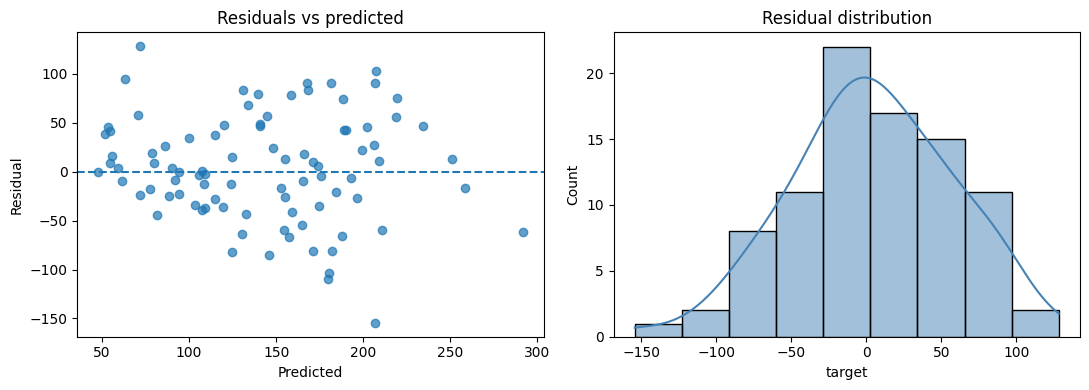

In [2]:
residuals = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(pred, residuals, alpha=.7)
axes[0].axhline(0, linestyle="--")
axes[0].set(xlabel="Predicted", ylabel="Residual", title="Residuals vs predicted")
sns.histplot(residuals, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Residual distribution")
plt.tight_layout()

## Ridge and Lasso
Regularization penalizes large coefficients. Ridge uses an L2 penalty and usually shrinks coefficients smoothly. Lasso uses an L1 penalty and can drive some coefficients to exactly zero. Tune the penalty using cross-validation, and scale features when the penalty should treat them comparably.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
for name, estimator in [("Ridge", Ridge(alpha=10)), ("Lasso", Lasso(alpha=0.1, max_iter=10000))]:
    pipe = make_pipeline(StandardScaler(), estimator)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    print(name, "CV R2 mean/std:", round(cv_r2.mean(), 3), round(cv_r2.std(), 3))

Ridge CV R2 mean/std: 0.48 0.039
Lasso CV R2 mean/std: 0.481 0.04


## Interpretation cautions
- A linear relationship can be useful even when the world is more complex, but inspect nonlinear patterns and residuals.
- Coefficients depend on feature units; scaled coefficients are easier to compare but need careful interpretation.
- R² can be negative on held-out data if the model performs worse than predicting the test-set mean.
- Correlation and fitted coefficients are not causal effects by themselves.

## Practice
1. Compute a baseline that predicts the training median.
2. Compare the baseline MAE with the linear model MAE.
3. Explain why RMSE penalizes large errors more than MAE.

In [4]:
baseline = np.repeat(y_train.median(), len(y_test))
print("Median baseline MAE:", round(mean_absolute_error(y_test, baseline), 2))
print("Linear model MAE:", round(mean_absolute_error(y_test, pred), 2))
print("RMSE squares residuals before averaging, so large errors carry more influence.")

Median baseline MAE: 62.74
Linear model MAE: 42.79
RMSE squares residuals before averaging, so large errors carry more influence.
